Silhouette Score: 0.5148
Davies-Bouldin Index (DBI): 0.6810


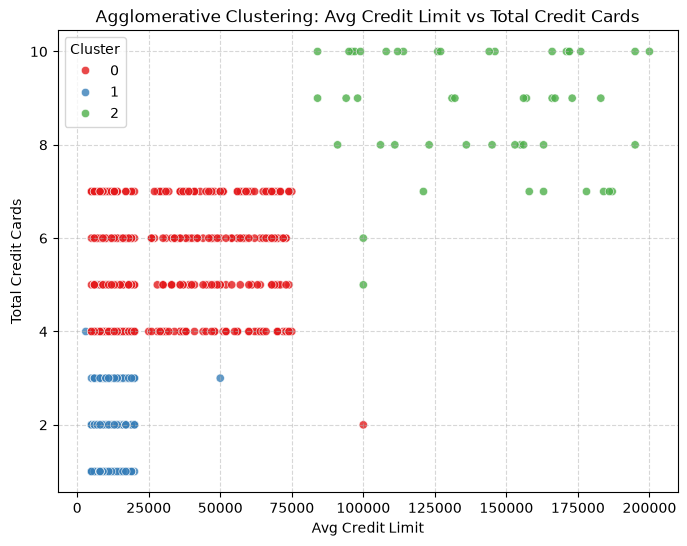

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# 1. Load the dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# 2. Select usable variables (dropping ID and serial number columns)
X = df.drop(columns=['Sl_No', 'Customer Key'])

# 3. Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Construct the Agglomerative Clustering model (using 3 clusters and Ward linkage)
model = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['Cluster'] = model.fit_predict(X_scaled)

# 5. Calculate evaluation metrics
sil_score = silhouette_score(X_scaled, df['Cluster'])
dbi_score = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi_score:.4f}")

# 6. Create scatterplot based on Avg_Credit_Limit and Total_Credit_Cards
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, 
    x='Avg_Credit_Limit', 
    y='Total_Credit_Cards', 
    hue='Cluster', 
    palette='Set1', 
    alpha=0.8
)
plt.title('Agglomerative Clustering: Avg Credit Limit vs Total Credit Cards')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('cluster_plot.png', bbox_inches='tight')
plt.show()